# Lab 04 : Détection d'objets dans une image avec YOLO

Ce notebook montre comment détecter des objets dans une image avec YOLO et la bibliothèque Ultralytics. Il est conçu pour l'environnement JupyterLab de formation avec GPU, mais il fonctionne aussi sur CPU pour de petites images.

## Objectifs pédagogiques

À la fin de ce notebook, vous saurez :

- Comprendre ce que renvoie une détection d'objets YOLO.
- Charger un modèle YOLO pré-entraîné.
- Lancer une détection sur une image.
- Afficher les boîtes englobantes et les scores de confiance.
- Filtrer les détections par confiance et par classe.
- Remplacer l'image d'exemple par votre propre image.

Vous comprendrez ainsi le processus d'inférence de YOLO, la structure des résultats de détection, le rôle du seuil de confiance et les méthodes de visualisation.

## Prérequis d'environnement

Le serveur GPU de formation dispose déjà de Python 3.11, de PyTorch avec CUDA, d'Ultralytics YOLO, d'OpenCV, de Pillow, de matplotlib et de numpy. L'image Docker du cours installe aussi Ultralytics via `requirements.txt`.

Si vous exécutez ce notebook sur votre propre machine et qu'ultralytics est absent, installez-le depuis un terminal :

~~~bash
python -m pip install ultralytics
~~~

N'installez pas de bibliothèques à répétition pendant la séance, sauf si le formateur vous le demande.

In [5]:
%pip install ultralytics

  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 3.4 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.3/48.3 MB 11.5 MB/s  0:00:04 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 847.1/847.1 kB 21.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.5/47.5 MB 19.0 MB/s  0:00:02m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 22.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.2/111.2 MB 20.3 MB/s  0:00:05m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 818.2/818.2 kB 18.1 MB/s  0:00:00
Using cached sympy-1.14.0-py3-none-any.whl (6.3 MB)
  Attempting uninstall: sympy
    Found existing installation: sympy 1.13.1
    Uninstalling sympy-1.13.1:
      Successfully uninstalled sympy-1.13.1━━━━━━━━━━━━━━━━━━━━━━━  1/10 [sympy]
  Attempting uninstall: setuptools━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  1/10 [sympy]
    Found existing installation: s

In [1]:
import sys
import importlib.util

required = ["ultralytics", "torch", "cv2", "PIL", "matplotlib", "numpy"]
print("Python :", sys.version)
for name in required:
    print(f"{name:12s}", "installé" if importlib.util.find_spec(name) else "manquant")

Python: 3.11.8 | packaged by conda-forge | (main, Feb 16 2024, 20:49:36) [Clang 16.0.6 ]
ultralytics  missing
torch        installed
cv2          missing
PIL          installed
matplotlib   installed
numpy        installed


In [2]:
import torch

DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Version de Torch :", torch.__version__)
print("CUDA disponible :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))
else:
    print("Utilisation du CPU. La démo fonctionne quand même, mais l'inférence sera plus lente.")

Torch version: 2.6.0
CUDA available: False
Using CPU. The demo still works, but inference will be slower.


## Étape 1 : préparer une image d'exemple

Le notebook utilise une image d'exemple publique d'Ultralytics, déjà présente dans `assets/`. Si elle est absente, il la télécharge. Si le réseau n'est pas disponible, déposez votre propre image dans ce dossier et modifiez IMAGE_PATH.

Image size: (810, 1080)


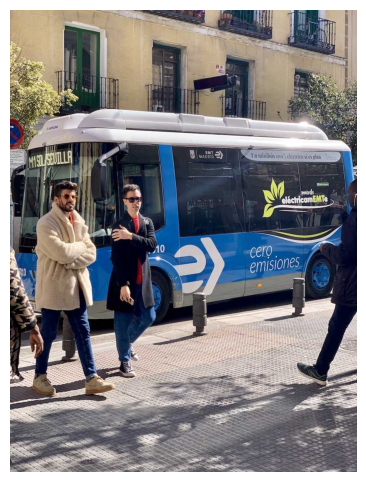

In [3]:
from pathlib import Path
from urllib.request import urlretrieve
from PIL import Image
import matplotlib.pyplot as plt

ASSET_DIR = Path("assets")
ASSET_DIR.mkdir(exist_ok=True)
IMAGE_PATH = ASSET_DIR / "yolo_bus.jpg"

if not IMAGE_PATH.exists():
    try:
        urlretrieve("https://ultralytics.com/images/bus.jpg", IMAGE_PATH)
        print("Image d'exemple téléchargée :", IMAGE_PATH)
    except Exception as exc:
        raise RuntimeError("Impossible de télécharger l'image d'exemple. Déposez votre propre image et indiquez son chemin dans IMAGE_PATH.") from exc

img = Image.open(IMAGE_PATH).convert("RGB")
print("Taille de l'image :", img.size)
plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.axis("off");

## Étape 2 : charger un modèle YOLO pré-entraîné

Nous utilisons yolov8n.pt, le petit modèle YOLOv8 « nano ». Il est rapide et adapté aux démonstrations en classe.

Lors de la première exécution, Ultralytics peut télécharger automatiquement le fichier de poids. Il est ensuite mis en cache dans le dossier courant ou dans le cache de l'utilisateur.

In [6]:
from ultralytics import YOLO

MODEL_NAME = "yolov8n.pt"
model = YOLO(MODEL_NAME)
print("Modèle chargé :", MODEL_NAME)

WARNING ⚠️ torchvision==0.28 is incompatible with torch==2.6.
Run 'pip install torchvision==0.21' to fix torchvision or 'pip install -U torch torchvision' to update both.
For a full compatibility table see https://github.com/pytorch/vision#installation
WARNING ⚠️ Ultralytics settings updated to the latest schema. Existing values were preserved where possible. 
View Ultralytics Settings with 'yolo settings' or at '/Users/atoukoffikougbanhoun/Library/Application Support/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
WARNING ⚠️ Download failure, retrying 1/3 https://github.com/ultralytics/assets/releases/download/v8.4.0/yolov8n.pt... HTTPSConnectionPool(host='github.com', port=443): Max retries exceeded with url: /ultralytics/assets/releases/download/v8.4.0/yolov8n.pt (Caused by ConnectTimeoutError(<HTTPSConnection(host='github.com', port=443) 

WARNING ⚠️ Download failure, retrying 2/3 https://github.com/ultralytics/assets/releases/download/v8.4.0/yolov8n.pt... Curl return value 56


curl: (56) OpenSSL SSL_read: SSL_ERROR_SYSCALL, errno 0                        

curl: (28) Failed to connect to github.com port 443 after 30004 ms: Timeout was reached
curl: (28) Failed to connect to github.com port 443 after 30006 ms: Timeout was reached
curl: (28) Failed to connect to github.com port 443 after 30002 ms: Timeout was reached
#######################################################################   99.9%

Model loaded: yolov8n.pt


######################################################################## 100.0%


## Étape 3 : lancer la détection

Paramètres importants :

- conf : seuil de confiance minimal.
- imgsz : taille de l'image utilisée pour l'inférence.
- device : identifiant du GPU (par exemple 0), ou "cpu".

Plus le seuil de confiance est élevé, plus les détections sont prudentes ; plus il est bas, plus il y a de détections, mais aussi de fausses détections.

In [7]:
results = model.predict(
    source=str(IMAGE_PATH),
    imgsz=640,
    conf=0.25,
    device=DEVICE,
    verbose=False,
)

result = results[0]
print("Nombre de détections :", len(result.boxes))

RuntimeError: operator torchvision::nms does not exist

## Étape 4 : visualiser les boîtes englobantes

Ultralytics peut dessiner automatiquement les boîtes, les étiquettes et les scores de confiance.

In [8]:
annotated_bgr = result.plot()
annotated_rgb = annotated_bgr[:, :, ::-1]

plt.figure(figsize=(10, 7))
plt.imshow(annotated_rgb)
plt.axis("off");

NameError: name 'result' is not defined

## Étape 5 : examiner les résultats de détection

Chaque détection comporte les coordonnées de sa boîte englobante, un score de confiance, un identifiant de classe et un nom de classe.

Ces résultats peuvent ensuite servir à compter des objets, déclencher une alerte, recadrer une cible, enregistrer un fichier JSON, alimenter une application métier, etc.

In [ ]:
import pandas as pd

rows = []
for box in result.boxes:
    cls_id = int(box.cls[0])
    conf = float(box.conf[0])
    x1, y1, x2, y2 = [float(v) for v in box.xyxy[0]]
    rows.append({
        "class_id": cls_id,
        "class_name": result.names[cls_id],
        "confidence": round(conf, 3),
        "x1": round(x1, 1),
        "y1": round(y1, 1),
        "x2": round(x2, 1),
        "y2": round(y2, 1),
    })

df = pd.DataFrame(rows)
df

## Étape 6 : filtrer les résultats

Dans une application, on filtre généralement par confiance, par classe, par zone ou par taille d'objet. L'exemple ci-dessous ne garde que les personnes et les véhicules détectés avec une confiance élevée.

In [ ]:
if df.empty:
    print("Aucune détection trouvée.")
else:
    target_classes = {"person", "car", "bus", "truck", "bicycle", "motorcycle"}
    filtered = df[(df["confidence"] >= 0.5) & (df["class_name"].isin(target_classes))]
    display(filtered)

## Étape 7 : utiliser votre propre image

Déposez une image dans ce dossier Jupyter, puis modifiez le chemin :

~~~python
IMAGE_PATH = Path("votre_image.jpg")
results = model.predict(source=str(IMAGE_PATH), conf=0.25, imgsz=640, device=DEVICE)
~~~

Formats conseillés : .jpg, .jpeg, .png. Si l'image est très grande, redimensionnez-la d'abord ou utilisez une valeur d'imgsz plus petite.

## Questions pour la discussion

- Que se passe-t-il si vous abaissez conf de 0,25 à 0,10 ?
- Quels faux positifs ou quels objets manqués observez-vous ?
- Quelles classes sont importantes pour votre propre cas d'usage ?
- Les résultats de détection doivent-ils déclencher une action automatique, ou faut-il d'abord une vérification humaine ?
- Quels enjeux de vie privée ou de sécurité apparaissent lorsqu'on détecte des personnes ou des véhicules ?

YOLO est utile, mais un système en production a besoin de contrôles de qualité des données, d'une surveillance, d'une analyse de l'impact sur la vie privée et d'une responsabilité humaine clairement définie.